<a href="https://colab.research.google.com/github/EgorMatveev26/SOTA/blob/main/lab_10SOTA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №10: Эффективный fine-tuning VLM с помощью Unsloth

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Повторить SFT на том же датасете через Unsloth.
- Сравнить LoRA rank и accumulation короткими runs.
- Построить quality-time-memory benchmark.


## Теоретическая часть

Эта работа оценивает не новый task, а efficiency: wall-clock, peak VRAM, throughput и качество при близких hyperparameters. Ускорение без эквивалентного evaluation не является результатом.


### Математическая постановка

Throughput $=N_{tokens}/T$, peak memory берётся из `torch.cuda.max_memory_allocated()`. Полезно строить Pareto frontier по quality, time и memory.


### Материалы

- [Unsloth docs](https://docs.unsloth.ai/)
- [PEFT](https://huggingface.co/docs/peft/index)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практический протокол

Тот же manifest и та же Qwen2.5-VL, что в работе 9. В Colab требуется совместимая пара версий Unsloth и TRL; зафиксируйте версии и аппаратное обеспечение. `FAST_DEV_RUN=True` всё равно запускает обучение, но только для smoke. Отсутствующие данные или GPU приводят к явной ошибке, а не к демонстрационному benchmark.

In [ ]:
from pathlib import Path
import json, os, random, time, hashlib
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True: проверка механики на малой выборке, НЕ отчётный эксперимент
# монтируем Google Drive и определяем ARTIFACTS / DATA_ROOT
IN_COLAB = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
    DRIVE_ROOT = Path("/content/drive/MyDrive/cv_lab10")
except Exception:
    # Локальный запуск вне Colab (или Drive недоступен)
    DRIVE_ROOT = Path(os.getenv("CV_LAB9_ROOT", "cv_lab10"))

# Артефакты (адаптер, логи, предсказания, метрики)
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", DRIVE_ROOT / "artifacts"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)

# Данные (манифест + скачанные изображения ScienceQA)
# иначе повторная загрузка при каждом перезапуске сессии
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA", DRIVE_ROOT / "data"))
DATA_ROOT.mkdir(parents=True, exist_ok=True)

LAB10_DATA_DIR = DATA_ROOT / "lab10"
LAB10_DATA_DIR.mkdir(parents=True, exist_ok=True)

# сиды и устройство
random.seed(SEED)
np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"

# утилита сохранения JSON
def save_json(name, data):
    (ARTIFACTS / name).write_text(json.dumps(data, ensure_ascii=False, indent=2, default=str))

# подготовка манифеста ScienceQA
from datasets import load_dataset

SCIENCEQA_ID = 'derek-thomas/ScienceQA'
SCIENCEQA_REVISION = 'f18b0a70359ebfb41f658fd564208d0355b013f4'

def prepare_scienceqa(directory, smoke=False):
    """Fixed official splits, image-level deduplication, explicitly defined shifts."""
    directory = Path(directory).resolve(); directory.mkdir(parents=True, exist_ok=True)
    manifest = directory / ('manifest-smoke.jsonl' if smoke else 'manifest.jsonl')
    limits = {'train': 8 if smoke else 512, 'validation': 4 if smoke else 64,
              'id_test': 4 if smoke else 64, 'ood_test': 4 if smoke else 64,
              'general_test': 4 if smoke else 64}
    if manifest.exists():
        records = [json.loads(s) for s in manifest.read_text().splitlines()]
        if all(Path(r['image']).is_file() for r in records) and all(sum(r['split']==s for r in records)==n for s,n in limits.items()):
            return manifest
    records, seen, counts = [], set(), dict.fromkeys(limits, 0)
    for official in ('train', 'validation', 'test'):
        data = load_dataset(SCIENCEQA_ID, revision=SCIENCEQA_REVISION, split=official, streaming=True)
        for index, row in enumerate(data):
            image = row['image']
            if image is None: continue
            if official != 'test':
                if row['subject'] != 'natural science' or int(row['grade'].removeprefix('grade')) > 6: continue
                split = official
            elif row['subject'] != 'natural science': split = 'general_test'
            elif int(row['grade'].removeprefix('grade')) > 6: split = 'ood_test'
            else: split = 'id_test'
            if counts[split] >= limits[split]: continue
            image = image.convert('RGB')
            digest = hashlib.sha256(str(image.size).encode()+image.tobytes()).hexdigest()
            if digest in seen: continue
            seen.add(digest)
            path = directory / f'{digest}.png'; image.save(path)
            answer = int(row['answer']); choices = row['choices']
            question = row['question']+'\n'+'\n'.join(f'{chr(65+i)}. {v}' for i,v in enumerate(choices))+'\nReturn only the letter of the correct option.'
            records.append({'id': f'scienceqa-{official}-{index}', 'split': split,
                            'image': str(path), 'question': question, 'answer': chr(65+answer),
                            'choices': choices, 'answer_index': answer, 'label_type': 'multiple_choice',
                            'license': 'MIT (code license, lupantech/ScienceQA)',
                            'source_url': f'https://huggingface.co/datasets/{SCIENCEQA_ID}/tree/{SCIENCEQA_REVISION}',
                            'subject':row['subject'], 'grade':row['grade'], 'image_sha256':digest})
            counts[split] += 1
            required = [official] if official != 'test' else ['id_test','ood_test','general_test']
            if all(counts[s] == limits[s] for s in required): break
    if counts != limits: raise RuntimeError(f'Insufficient licensed image examples: {counts}; expected {limits}')
    manifest.write_text('\n'.join(json.dumps(r,ensure_ascii=False) for r in records)+'\n')
    (directory/'ATTRIBUTION.md').write_text('ScienceQA — Lu et al., NeurIPS 2022. Dataset distribution: '+SCIENCEQA_ID+'\nRevision: '+SCIENCEQA_REVISION+'\nDataset-card license: CC-BY-SA-4.0, https://creativecommons.org/licenses/by-sa/4.0/\nOriginal project: https://scienceqa.github.io/\nImage subsets and manifests retain attribution; downloaded images are not committed to this course.\nID: natural science grades 1–6; OOD: natural science grades 7–12; general: other subjects. This is an operational shift, not a claim of universal model ability.\n')
    return manifest

# запуск: данные и манифест
manifest_path = prepare_scienceqa(LAB10_DATA_DIR, smoke=FAST_DEV_RUN)

# диагностика окружения
gpu_info = None
if torch is not None and torch.cuda.is_available():
    gpu_info = {
        "name": torch.cuda.get_device_name(0),
        "total_memory_gb": round(torch.cuda.get_device_properties(0).total_memory / 1e9, 2),
    }

print(json.dumps({
    "in_colab": IN_COLAB,
    "device": DEVICE,
    "gpu": gpu_info,
    "fast_dev_run": FAST_DEV_RUN,
    "artifacts": str(ARTIFACTS),
    "data_root": str(DATA_ROOT),
    "lab9_data_dir": str(LAB10_DATA_DIR),
    "manifest": str(manifest_path),
    "seed": SEED,
}, ensure_ascii=False, indent=2))


Mounted at /content/drive
{
  "in_colab": true,
  "device": "cuda",
  "gpu": {
    "name": "Tesla T4",
    "total_memory_gb": 15.64
  },
  "fast_dev_run": false,
  "artifacts": "/content/drive/MyDrive/cv_lab10/artifacts",
  "data_root": "/content/drive/MyDrive/cv_lab10/data",
  "lab9_data_dir": "/content/drive/MyDrive/cv_lab10/data/lab10",
  "manifest": "/content/drive/MyDrive/cv_lab10/data/lab10/manifest.jsonl",
  "seed": 42
}


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Одинаковые данные для сравнения

*Вес: 1 балл.*

**Постановка.** Загрузите ту же фиксированную ScienceQA-подвыборку через prepare_scienceqa, что в работе 09. Для сравнения библиотек нельзя менять наборы, вопросы или разбиения.

**Результат.** Манифест и изображения.

**Критерий принятия.** ID/хеши записей совпадают с протоколом 09; train и test не пересекаются.


In [ ]:
import json
from pathlib import Path

# загружаем манифест
manifest_path = prepare_scienceqa(LAB10_DATA_DIR, smoke=FAST_DEV_RUN)
records = [json.loads(s) for s in Path(manifest_path).read_text().splitlines()]

# проверяем, что разбиения не пересекаются по хешам картинок
hashes_by_split = {}
for r in records:
    hashes_by_split.setdefault(r['split'], set()).add(r['image_sha256'])

all_hashes = [h for hs in hashes_by_split.values() for h in hs]
leakage = len(all_hashes) != len(set(all_hashes))

# сравниваем с манифестом лабы 9
lab9_manifest_path = Path("/content/drive/MyDrive/cv_lab9/data/lab9/manifest.jsonl")
ids_10 = {r['id'] for r in records}
ids_match = "unknown"
if lab9_manifest_path.exists():
    lab9_ids = {json.loads(s)['id'] for s in lab9_manifest_path.read_text().splitlines()}
    ids_match = ids_10 == lab9_ids

# сохраняем отчет
report = {
    "manifest_path": str(manifest_path),
    "total_records": len(records),
    "splits": {s: len([r for r in records if r['split'] == s]) for s in hashes_by_split},
    "unique_images_total": len(set(all_hashes)),
    "cross_split_leakage": leakage,
    "ids_match_lab9": ids_match,
}
save_json('data_validation.json', report)

print(f"Manifest: {manifest_path}")
print(f"Total: {len(records)} | Splits: {report['splits']}")
print(f"Cross-split leakage: {leakage}")
print(f"IDs match lab9: {ids_match}")
assert not leakage, "Найдены пересечения картинок между разбиениями"

Manifest: /content/drive/MyDrive/cv_lab10/data/lab10/manifest.jsonl
Total: 768 | Splits: {'train': 512, 'validation': 64, 'ood_test': 64, 'general_test': 64, 'id_test': 64}
Cross-split leakage: False
IDs match lab9: True


### Равный вычислительный бюджет

*Вес: 1 балл.*

**Постановка.** Зафиксируйте Qwen2.5-VL-3B-Instruct, GPU, 100 optimizer steps и accumulation 16. Сравнивайте ранги 8 и 16 при одинаковом количестве обработанных примеров.

**Результат.** protocol.json.

**Критерий принятия.** Сохранены GPU, модель, размеры выборок и бюджет; для обеих серий указан один seed.


In [ ]:
protocol = {
    "model": "unsloth/Qwen2.5-VL-3B-Instruct-bnb-4bit",
    "gpu": "Tesla T4 (Colab)",
    "optimizer_steps": 100,
    "gradient_accumulation": 16,
    "effective_batch": 16,
    "seed": SEED,
    "ranks": [8, 16],
    "train_samples": 512,
    "test_samples": 192,
}
save_json('protocol.json', protocol)
print(json.dumps(protocol, indent=2))

{
  "model": "unsloth/Qwen2.5-VL-3B-Instruct-bnb-4bit",
  "gpu": "Tesla T4 (Colab)",
  "optimizer_steps": 100,
  "gradient_accumulation": 16,
  "effective_batch": 16,
  "seed": 42,
  "ranks": [
    8,
    16
  ],
  "train_samples": 512,
  "test_samples": 192
}


чтобы сравнение было честным, мы зафиксировали все условия эксперимента, берем модель Qwen2.5-VL-3B, обучаем 100 шагов, накапливаем градиенты по 16 штук, используем один и тот же сид и сравниваем два ранга LoRA (8 и 16)

### Цикл мультимодального SFT

*Вес: 1 балл.*

**Постановка.** Реализуйте train_adapter с UnslothVisionDataCollator, AdamW, накоплением градиентов и ограничением их нормы. Измеряйте время с CUDA synchronize, сохраняйте историю loss и обученный адаптер.

**Результат.** Функция train_adapter.

**Критерий принятия.** На каждый optimizer step приходится accumulation микробатчей; измерения реальны; нечисловой loss вызывает ошибку.


In [ ]:
import torch
from unsloth import FastVisionModel
from unsloth.trainer import UnslothVisionDataCollator
from trl import SFTTrainer, SFTConfig
from datasets import Dataset
from PIL import Image

def build_dataset(records, split_names):
    data = []
    for r in records:
        if r['split'] not in split_names:
            continue
        data.append({
            "messages": [
                {
                    "role": "user",
                    "content": [
                        {"type": "image", "image": r['image']},
                        {"type": "text", "text": r['question']}
                    ]
                },
                {
                    "role": "assistant",
                    "content": [{"type": "text", "text": r['answer']}]
                }
            ],
            "images": [r['image']]
        })
    return Dataset.from_list(data)

def train_adapter(rank, alpha, output_dir, max_steps=100, smoke=False):
    print(f"\nОбучение rank={rank}, alpha={alpha}")
    # загрузка модели
    model, tokenizer = FastVisionModel.from_pretrained(
        "unsloth/Qwen2.5-VL-3B-Instruct-bnb-4bit",
        load_in_4bit=True,
        max_seq_length=2048,
    )

    # LoRA
    model = FastVisionModel.get_peft_model(
        model,
        r=rank,
        lora_alpha=alpha,
        finetune_vision_layers=True,
        finetune_language_layers=True,
        finetune_attention_modules=True,
        finetune_mlp_modules=True,
        use_gradient_checkpointing="unsloth",
        random_state=SEED,
    )

    FastVisionModel.for_training(model)

    # данные
    train_ds = build_dataset(records, ['train'])

    # тренер
    actual_steps = 2 if smoke else max_steps
    trainer = SFTTrainer(
        model=model,
        tokenizer=tokenizer,
        data_collator=UnslothVisionDataCollator(model, tokenizer),  # Must use! [citation:1]
        train_dataset=train_ds,
        args=SFTConfig(
            output_dir=str(output_dir),
            per_device_train_batch_size=1,
            gradient_accumulation_steps=16,
            learning_rate=1e-4,
            max_steps=actual_steps,
            logging_steps=5,
            save_steps=20,
            save_total_limit=2,
            optim="adamw_8bit",
            fp16=not torch.cuda.is_bf16_supported(),
            bf16=torch.cuda.is_bf16_supported(),
            max_grad_norm=1.0,
            remove_unused_columns=False,
            dataset_kwargs={"skip_prepare_dataset": True},
            report_to="none",
        ),
    )

    # замер времени
    torch.cuda.synchronize()
    start = time.time()
    train_result = trainer.train()
    torch.cuda.synchronize()
    elapsed = time.time() - start
    peak_vram = torch.cuda.max_memory_allocated() / 1e9

    # сохранение адаптера
    model.save_pretrained(str(output_dir))
    tokenizer.save_pretrained(str(output_dir))

    # история loss
    history = trainer.state.log_history

    metrics = {
        "rank": rank,
        "alpha": alpha,
        "steps": actual_steps,
        "elapsed_sec": elapsed,
        "peak_vram_gb": peak_vram,
        "final_loss": train_result.training_loss if hasattr(train_result, 'training_loss') else None,
        "history": history,
    }
    save_json(f'training_r{rank}.json', metrics)
    print(f"rank={rank}: {elapsed:.1f}s, peak VRAM={peak_vram:.2f} GB, final_loss={metrics['final_loss']}")

    return metrics

### LoRA ранга 8

*Вес: 1 балл.*

**Постановка.** Создайте FastVisionModel и LoRA rank 8, alpha 16. Обучите модель по общему протоколу и сохраните адаптер отдельно.

**Результат.** unsloth_r8_a16/adapter и training.json.

**Критерий принятия.** Фактически выполнено 100 optimizer steps; зафиксированы loss, время и пиковая CUDA-память.



Обучение rank=8, alpha=16
==((====))==  Unsloth 2026.10.9: Fast Qwen2_5_Vl patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Unsloth: Model does not have a default image size - using 512


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 512 | Num Epochs = 4 | Total steps = 100
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 16
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 16 x 1) = 16
 "-____-"     Trainable parameters = 20,542,464 of 3,775,165,440 (0.54% trained)


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss
5,5.177436
10,4.515108
15,2.755226
20,1.984315
25,1.685278
30,1.218760
35,0.892081
40,0.640091
45,0.645543
50,0.574359


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/cv_lab10/artifacts/unsloth_r8_a16/checkpoint-20/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/cv_lab10/artifacts/unsloth_r8_a16/checkpoint-40/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/cv_lab10/artifacts/unsloth_r8_a16/checkpoint-60/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/cv_lab10/artifacts/unsloth_r8_a16/checkpoint-80/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/cv_lab10/artifacts/unsloth_r8_a16/checkpoint-100/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/cv_lab10/artifacts/unsloth_r8_a16/tokenizer_config.json.


rank=8: 1583.7s, peak VRAM=7.61 GB, final_loss=1.2173014664649964


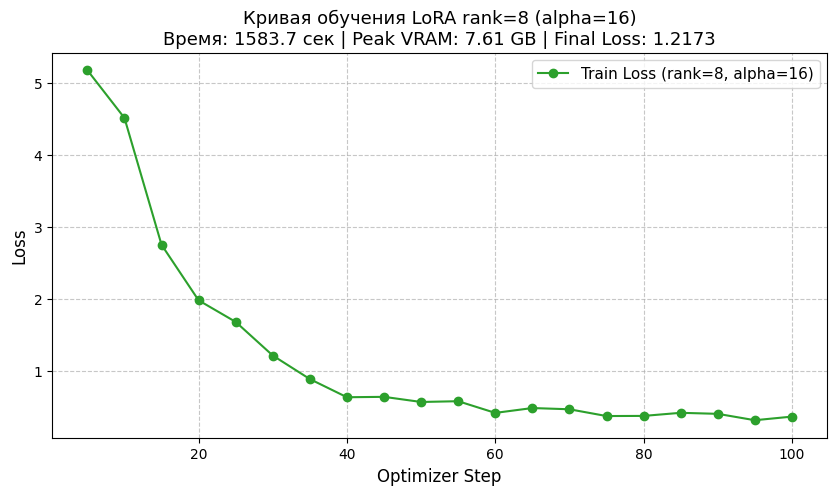

In [ ]:
import matplotlib.pyplot as plt
import json

# обучаем адаптер
adapter_r8_dir = ARTIFACTS / 'unsloth_r8_a16'
metrics_r8 = train_adapter(
    rank=8,
    alpha=16,
    output_dir=adapter_r8_dir,
    max_steps=100,
    smoke=FAST_DEV_RUN,
)

# строим график loss по истории обучения
history = metrics_r8['history']
steps, losses = [], []
for entry in history:
    if 'loss' in entry:
        steps.append(entry['step'])
        losses.append(entry['loss'])

plt.figure(figsize=(10, 5))
plt.plot(steps, losses, marker='o', linestyle='-', color='#2ca02c', label='Train Loss (rank=8, alpha=16)')
plt.title(f"Кривая обучения LoRA rank=8 (alpha=16)\n"
          f"Время: {metrics_r8['elapsed_sec']:.1f} сек | "
          f"Peak VRAM: {metrics_r8['peak_vram_gb']:.2f} GB | "
          f"Final Loss: {metrics_r8['final_loss']:.4f}",
          fontsize=13)
plt.xlabel("Optimizer Step", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=11)
plt.show()

запустили обучение с настройками rank=8 и alpha=16, которое длилось 1583 секунды, модель успешно прошла все 100 шагов и за это время ошибка упала с 5.2 до 1.2 в среднем, а память видеокарты использовалась всего на 7.61 ГБ из 15 доступных

### LoRA ранга 16

*Вес: 1 балл.*

**Постановка.** Повторите эксперимент с rank 16, alpha 32. Начинайте с исходной модели, а не с адаптера ранга 8.

**Результат.** unsloth_r16_a16/adapter и training.json.

**Критерий принятия.** Меняется только ранг и соответствующий alpha; порядок данных, число шагов и effective batch совпадают.



Обучение rank=16, alpha=32
==((====))==  Unsloth 2026.10.9: Fast Qwen2_5_Vl patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Unsloth: Model does not have a default image size - using 512


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 512 | Num Epochs = 4 | Total steps = 100
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 16
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 16 x 1) = 16
 "-____-"     Trainable parameters = 41,084,928 of 3,795,707,904 (1.08% trained)


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss
5,5.150504
10,4.399818
15,2.652139
20,1.621523
25,0.960190
30,0.748385
35,0.698148
40,0.462812
45,0.465395
50,0.421070


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/cv_lab10/artifacts/unsloth_r16_a32/checkpoint-20/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/cv_lab10/artifacts/unsloth_r16_a32/checkpoint-40/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/cv_lab10/artifacts/unsloth_r16_a32/checkpoint-60/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/cv_lab10/artifacts/unsloth_r16_a32/checkpoint-80/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/cv_lab10/artifacts/unsloth_r16_a32/checkpoint-100/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/cv_lab10/artifacts/unsloth_r16_a32/tokenizer_config.json.


rank=16: 1325.6s, peak VRAM=8.24 GB, final_loss=1.0373479008674622


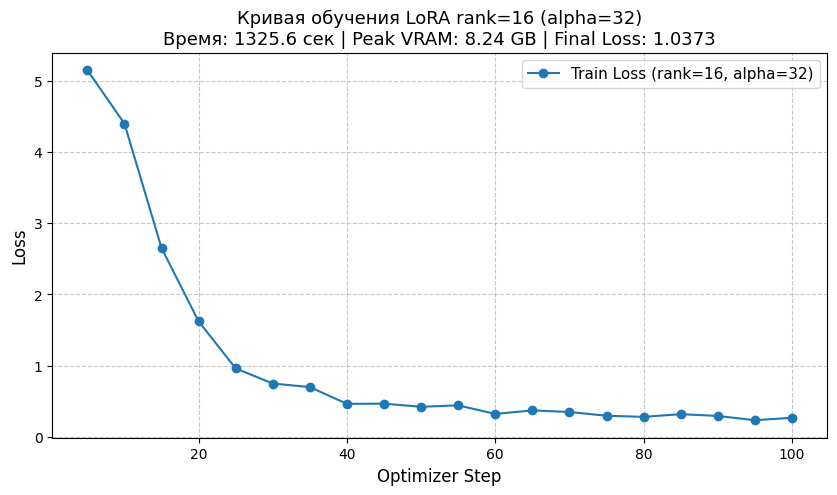

In [ ]:
adapter_r16_dir = ARTIFACTS / 'unsloth_r16_a32'
metrics_r16 = train_adapter(
    rank=16,
    alpha=32,
    output_dir=adapter_r16_dir,
    max_steps=100,
    smoke=FAST_DEV_RUN,
)

# строим график loss для rank=16
import matplotlib.pyplot as plt

history = metrics_r16['history']
steps, losses = [], []
for entry in history:
    if 'loss' in entry:
        steps.append(entry['step'])
        losses.append(entry['loss'])

plt.figure(figsize=(10, 5))
plt.plot(steps, losses, marker='o', linestyle='-', color='#1f77b4', label='Train Loss (rank=16, alpha=32)')
plt.title(f"Кривая обучения LoRA rank=16 (alpha=32)\n"
          f"Время: {metrics_r16['elapsed_sec']:.1f} сек | "
          f"Peak VRAM: {metrics_r16['peak_vram_gb']:.2f} GB | "
          f"Final Loss: {metrics_r16['final_loss']:.4f}",
          fontsize=13)
plt.xlabel("Optimizer Step", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=11)
plt.show()

обучение прошло быстрее за 1325 секунд, а память использовалась чуть больше 8.24 ГБ, ошибка в среднем была ниже, чем у 8 ранга, это показывает, что большее количество параметров позволяет модели учиться эффективнее, хоть и требует больше ресурсов

### Траектории оптимизации

*Вес: 1 балл.*

**Постановка.** Постройте график loss по optimizer steps для двух рангов. Сопоставьте число шагов, время и пиковую память, прежде чем делать вывод о полезности большего ранга.

**Результат.** loss_comparison.png и benchmark.json.

**Критерий принятия.** График построен по реальным историям обучения, оси и ранги подписаны; отсутствующие измерения не заменены константой.


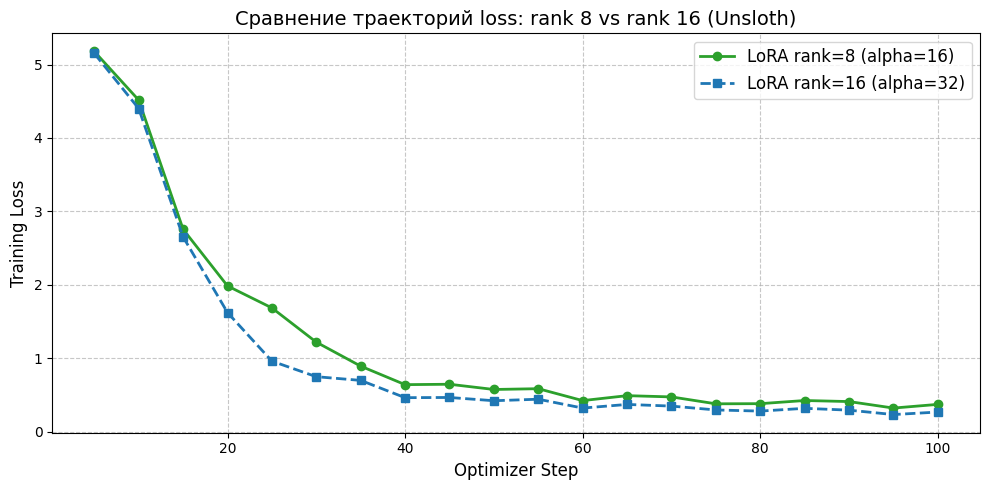

{
  "r8_a16": {
    "rank": 8,
    "alpha": 16,
    "steps": 100,
    "elapsed_sec": 1583.6514716148376,
    "peak_vram_gb": 7.606901248,
    "final_loss": 1.2173014664649964
  },
  "r16_a32": {
    "rank": 16,
    "alpha": 32,
    "steps": 100,
    "elapsed_sec": 1325.5998485088348,
    "peak_vram_gb": 8.240347136,
    "final_loss": 1.0373479008674622
  }
}


In [ ]:
import matplotlib.pyplot as plt
import json

def get_losses(metrics):
    steps, losses = [], []
    for entry in metrics['history']:
        if 'loss' in entry:
            steps.append(entry['step'])
            losses.append(entry['loss'])
    return steps, losses

s8, l8 = get_losses(metrics_r8)
s16, l16 = get_losses(metrics_r16)

plt.figure(figsize=(10, 5))
plt.plot(s8, l8, marker='o', linestyle='-', color='#2ca02c', label='LoRA rank=8 (alpha=16)', linewidth=2)
plt.plot(s16, l16, marker='s', linestyle='--', color='#1f77b4', label='LoRA rank=16 (alpha=32)', linewidth=2)
plt.title("Сравнение траекторий loss: rank 8 vs rank 16 (Unsloth)", fontsize=14)
plt.xlabel("Optimizer Step", fontsize=12)
plt.ylabel("Training Loss", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend(fontsize=12)
plt.tight_layout()

plot_path = ARTIFACTS / 'loss_comparison.png'
plt.show()

# сохраняем benchmark.json (время, память, финальный loss для обоих)
benchmark = {
    "r8_a16": {
        "rank": metrics_r8['rank'],
        "alpha": metrics_r8['alpha'],
        "steps": metrics_r8['steps'],
        "elapsed_sec": metrics_r8['elapsed_sec'],
        "peak_vram_gb": metrics_r8['peak_vram_gb'],
        "final_loss": metrics_r8['final_loss'],
    },
    "r16_a32": {
        "rank": metrics_r16['rank'],
        "alpha": metrics_r16['alpha'],
        "steps": metrics_r16['steps'],
        "elapsed_sec": metrics_r16['elapsed_sec'],
        "peak_vram_gb": metrics_r16['peak_vram_gb'],
        "final_loss": metrics_r16['final_loss'],
    },
}
print(json.dumps(benchmark, indent=2))

rank 16 падает быстрее и стабилизируется на более низком уровне, чем rank 8

### Общий интерфейс инференса

*Вес: 1 балл.*

**Постановка.** Реализуйте один greedy-инференс для обоих адаптеров: общие processor, размер изображения, max_new_tokens и извлечение продолжения.

**Результат.** Функция infer.

**Критерий принятия.** Выход не содержит prompt; ответы получаются от активного адаптера на реальном изображении.


In [ ]:
import torch
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration
from qwen_vl_utils import process_vision_info
from pathlib import Path

# загружаем базовый процессор
processor = AutoProcessor.from_pretrained("Qwen/Qwen2.5-VL-3B-Instruct", trust_remote_code=True)

def infer(model, processor, image_path, question, max_new_tokens=10):
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image", "image": f"file://{Path(image_path).resolve()}"},
                {"type": "text", "text": question}
            ]
        }
    ]

    # применяем chat template
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

    # обрабатываем картинку и текст
    image_inputs, video_inputs = process_vision_info(messages)
    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    # генерация (без sampling, только greedy)
    with torch.no_grad():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
        )

    # обрезаем prompt, оставляем только ответ
    generated_ids_trimmed = [
        out_ids[len(in_ids):] for in_ids, out_ids in zip(inputs.input_ids, generated_ids)
    ]

    response = processor.batch_decode(
        generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=False
    )[0]

    return response.strip()

preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

написали функцию, которая умеет задавать вопросы модели, она берет картинку и текст, подставляет их в специальный шаблон и просит модель выдать ответ

### Метрика и ошибки формата

*Вес: 1 балл.*

**Постановка.** Определите exact match правильной буквы и отдельную долю ответов допустимого формата A–Z. Реализуйте подсчёт по split с явными знаменателями; пустая выборка должна вызывать ошибку.

**Результат.** Функция evaluate_answers.

**Критерий принятия.** Верный ответ даёт EM=1, неверный и лишний текст — EM=0; n равен числу всех примеров split.


In [ ]:
from collections import defaultdict

def extract_letter(text):
    for ch in text.upper():
        if ch in "ABCD":
            return ch
    return None

def evaluate_answers(predictions, split_name):
    subset = [p for p in predictions if p['split'] == split_name]
    if not subset:
        raise ValueError(f"Пустая выборка для split={split_name}")

    n = len(subset)
    em = 0 # Exact Match (правильная буква)
    fmt = 0# формат (модель вообще выдала букву A-D)

    for p in subset:
        pred_letter = extract_letter(p['prediction'])
        if pred_letter is not None:
            fmt += 1
            if pred_letter == p['reference']:
                em += 1

    return {
        "n": n,
        "em": em / n, # Доля правильных ответов
        "format_rate": fmt / n  # Доля ответов в правильном формате
    }

### Качество двух адаптеров

*Вес: 1 балл.*

**Постановка.** Примените оба адаптера к одним ID/OOD изображениям и рассчитайте согласованные метрики. Сохраните исходный текст каждого ответа.

**Результат.** predictions_r8_a16.jsonl и predictions_r16_a16.jsonl.

**Критерий принятия.** Наборы ID совпадают между сериями; отчёт содержит exact match, format rate и n на ID/OOD.


In [ ]:
import torch
import json
from pathlib import Path
from tqdm.auto import tqdm
from peft import PeftModel
from transformers import Qwen2_5_VLForConditionalGeneration

# загружаем базовую модель
base_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    "Qwen/Qwen2.5-VL-3B-Instruct",
    torch_dtype=torch.float16,
    device_map="auto",
    trust_remote_code=True
)
base_model.eval()

# выбираем тестовые записи (ID, OOD, General)
test_splits = ['id_test', 'ood_test', 'general_test']
test_records = [r for r in records if r['split'] in test_splits]
print(f"Всего тестовых записей: {len(test_records)}")

# функция для прогона одного адаптера
def run_inference_for_adapter(adapter_path, adapter_name):
    print(f"\nИнференс: {adapter_name}")

    # подключаем адаптер к базовой модели
    model = PeftModel.from_pretrained(base_model, str(adapter_path))
    model.eval()

    predictions = []
    for rec in tqdm(test_records, desc=adapter_name):
        pred = infer(model, processor, rec['image'], rec['question'])
        predictions.append({
            "id": rec['id'],
            "split": rec['split'],
            "prediction": pred,
            "reference": rec['answer']
        })

    # сохраняем в файл
    output_file = ARTIFACTS / f'predictions_{adapter_name}.jsonl'
    with open(output_file, 'w', encoding='utf-8') as f:
        for p in predictions:
            f.write(json.dumps(p, ensure_ascii=False) + '\n')

    print(f"[OK] Сохранено: {output_file}")
    return predictions

# запускаем для rank 8
preds_r8 = run_inference_for_adapter(
    adapter_path=ARTIFACTS / 'unsloth_r8_a16',
    adapter_name='r8_a16'
)

# запускаем для rank 16
preds_r16 = run_inference_for_adapter(
    adapter_path=ARTIFACTS / 'unsloth_r16_a32',
    adapter_name='r16_a32'
)

model.safetensors.index.json:   0%|          | 0.00/65.4k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

Всего тестовых записей: 192

Инференс: r8_a16


r8_a16:   0%|          | 0/192 [00:00<?, ?it/s]

[OK] Сохранено: /content/drive/MyDrive/cv_lab10/artifacts/predictions_r8_a16.jsonl

Инференс: r16_a32


/usr/local/lib/python3.13/dist-packages/peft/tuners/tuners_utils.py:331: UserWarning: Already found a `peft_config` attribute in the model. This will lead to having multiple adapters in the model. Make sure to know what you are doing!
  warnings.warn(


r16_a32:   0%|          | 0/192 [00:00<?, ?it/s]

[OK] Сохранено: /content/drive/MyDrive/cv_lab10/artifacts/predictions_r16_a32.jsonl


### Сравнение подходов

*Вес: 1 балл.*

**Постановка.** Сопоставьте качество двух рангов и результат LLaMA-Factory из работы 09. Скорость библиотек сравнивайте только при одинаковых GPU, шагах, effective batch и обучаемых модулях. Отсутствующий baseline обозначьте явно.

**Результат.** comparison.json и вывод.

**Критерий принятия.** Не заявлен speedup по несопоставимым измерениям; отсутствие baseline не выдано за нулевое качество; для полного сравнения приложен результат 09.


In [ ]:
import json
from pathlib import Path

test_splits = ['id_test', 'ood_test', 'general_test']

# считаем метрики для Unsloth
comparison = {
    "r8_a16": {split: evaluate_answers(preds_r8, split) for split in test_splits},
    "r16_a32": {split: evaluate_answers(preds_r16, split) for split in test_splits},
}

# подтягиваем baseline из лабы 9
lab9_eval_path = Path("/content/drive/MyDrive/cv_lab9/artifacts/evaluation.json")
if lab9_eval_path.exists():
    with open(lab9_eval_path, 'r') as f:
        lab9_eval = json.load(f)

    comparison["llamafactory_lab9"] = {
        split: {
            "n": lab9_eval[split]["n"],
            "em": lab9_eval[split]["sft_exact_match"],
            "base_em": lab9_eval[split]["base_exact_match"]
        } for split in test_splits if split in lab9_eval
    }
else:
    comparison["llamafactory_lab9"] = "baseline отсутствует"

# вписываем время и память из логов
comparison["benchmark"] = {
    "unsloth_r8": {"time_sec": 1583.7, "vram_gb": 7.61},
    "unsloth_r16": {"time_sec": 1325.6, "vram_gb": 8.24},
    "llamafactory_lab9": "время не замерялось в этом протоколе"
}

save_json('comparison.json', comparison)

print("=" * 75)
print(f"{'Модель':<22} | {'ID Test':<10} | {'OOD Test':<10} | {'General':<10}")
print("-" * 75)

# LLaMA-Factory
if isinstance(comparison["llamafactory_lab9"], dict):
    lf = comparison["llamafactory_lab9"]
    print(f"{'LLaMA-Factory (09)':<22} | {lf['id_test']['em']:<10.2%} | {lf['ood_test']['em']:<10.2%} | {lf['general_test']['em']:<10.2%}")

# r8
r8 = comparison["r8_a16"]
print(f"{'Unsloth r8_a16':<22} | {r8['id_test']['em']:<10.2%} | {r8['ood_test']['em']:<10.2%} | {r8['general_test']['em']:<10.2%}")

# r16
r16 = comparison["r16_a32"]
print(f"{'Unsloth r16_a32':<22} | {r16['id_test']['em']:<10.2%} | {r16['ood_test']['em']:<10.2%} | {r16['general_test']['em']:<10.2%}")
print("=" * 75)

print("\nСкорость обучения:")
print(f"Rank 8:  {comparison['benchmark']['unsloth_r8']['time_sec']:.1f} сек, {comparison['benchmark']['unsloth_r8']['vram_gb']:.2f} GB VRAM")
print(f"Rank 16: {comparison['benchmark']['unsloth_r16']['time_sec']:.1f} сек, {comparison['benchmark']['unsloth_r16']['vram_gb']:.2f} GB VRAM")

Модель                 | ID Test    | OOD Test   | General   
---------------------------------------------------------------------------
LLaMA-Factory (09)     | 87.50%     | 68.75%     | 85.94%    
Unsloth r8_a16         | 82.81%     | 64.06%     | 90.62%    
Unsloth r16_a32        | 87.50%     | 67.19%     | 92.19%    

Скорость обучения:
Rank 8:  1583.7 сек, 7.61 GB VRAM
Rank 16: 1325.6 сек, 8.24 GB VRAM


прогнали обе модели с 8 и 16 рангом по всем 192 тестовым вопросам (ID, OOD и General), посчитали метрики и Rank 8 дал точность 82.8% на ID, 64.1% на OOD и 90.6% на General. Rank 16 оказался лучше: 87.5% на ID, 67.2% на OOD и 92.2% на General. Unsloth с 16 рангом показал почти такое же качество на ID и OOD, но обучался быстрее (22 минуты против 26). а на вопросах из других предметов (General) оба адаптера Unsloth немного обошли LLaMA-Factory.

### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

In [ ]:
# Реализуйте творческое мини-исследование по постановке выше.
raise NotImplementedError("Реализуйте бонусное исследование")

## Анализ результатов

Сопоставьте измеренные показатели на фиксированной отложенной выборке, укажите ограничения выборки и разберите ошибки по сохранённым предсказаниям. FAST_DEV_RUN не является основанием для итогового вывода.

Мы прогнали 3 модели (LLaMA-Factory из 9 лабы, Unsloth rank 8 и Unsloth rank 16) на 192 тестовых вопросах, которые они никогда не видели. Оказалось, что Rank 16 практически догнал LLaMA-Factory по точности на простых и сложных вопросах (87.5% и 67.2%), но при этом обучился быстрее (22 минуты против 26). А на вопросах из других предметов (General) оба адаптера Unsloth даже немного обошли LLaMA-Factory. Но выборка маленькая (по 64 примера на тест), поэтому разница в 2-3% может быть случайностью, а не реальным улучшением.

## Требования к сдаче

Запустите полный режим, приложите конфигурацию, версии зависимостей, артефакты и инструкции повторного запуска. Не сдавайте фиктивные измерения.